# Xabi Alonso's Leverkusen in six charts

Notebook 01 answered one question (how Leverkusen get the ball from the goalkeeper into midfield). This one tests
the main ideas people use to describe Alonso's team against the same data: StatsBomb open data, all 34 of
Leverkusen's 2023/24 Bundesliga matches. "Opponents" = the other team in those same matches.

| Chart | Idea tested |
| --- | --- |
| 04 | The 3-4-2-1: three centre-backs, two wing-backs, a double pivot, two 10s |
| 05 | Control: more of the ball and more of the pitch than every opponent |
| 06 | Where they win the ball back |
| 07 | Wing-backs as attackers |
| 08 | Central play, not crosses |
| 09 | Late goals ("Xabi time") |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())
RAW = REPO / "data" / "raw" / "9_281"
FIGS = ROOT / "reports" / "figures"
LEV = "Bayer Leverkusen"
RED, GREY, DARK, MUTED, LIGHT, PINK = "#E32221", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#F2A3A3"
SRC = "Data: StatsBomb open data, Bundesliga 2023/24 (Leverkusen's 34 league matches)"
from matplotlib import font_manager
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})

def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)

E = pd.read_parquet(RAW / "events.parquet").sort_values(["match_id", "index"]).reset_index(drop=True)
M = pd.read_parquet(RAW / "matches.parquet")
xy = lambda v: (v[0], v[1]) if v is not None and not isinstance(v, float) and len(v) else (np.nan, np.nan)
E[["x", "y"]] = E.location.map(xy).tolist()
E[["ex", "ey"]] = E.pass_end_location.where(E.type == "Pass", E.carry_end_location).map(xy).tolist()
for c in ["pass_cross", "pass_goal_assist", "pass_shot_assist"]:
    E[c] = E[c].fillna(False).astype(bool)
E["side"] = np.where(E.team == LEV, "Leverkusen", "Opponents")
P = E[E.type == "Pass"]
M["lev_home"] = M.home_team == LEV
M["gf"] = np.where(M.lev_home, M.home_score, M.away_score)
M["ga"] = np.where(M.lev_home, M.away_score, M.home_score)
M["opp"] = np.where(M.lev_home, M.away_team, M.home_team)
M["res"] = np.where(M.gf > M.ga, "W", np.where(M.gf == M.ga, "D", "L"))
SHORT = {"Lukáš Hrádecký": "Hrádecký", "Odilon Kossonou": "Kossounou", "Jonathan Tah": "Tah",
         "Edmond Fayçal Tapsoba": "Tapsoba", "Jeremie Frimpong": "Frimpong", "Granit Xhaka": "Xhaka",
         "Exequiel Alejandro Palacios": "Palacios", "Alejandro Grimaldo García": "Grimaldo", "Jonas Hofmann": "Hofmann",
         "Florian Wirtz": "Wirtz", "Victor Okoh Boniface": "Boniface", "Robert Andrich": "Andrich",
         "Piero Martín Hincapié Reyna": "Hincapié", "Patrik Schick": "Schick", "Josip Stanišić": "Stanišić",
         "Nathan Tella": "Tella", "Amine Adli": "Adli", "Adam Hložek": "Hložek"}
print(M.res.value_counts().to_dict(), "goals", M.gf.sum(), "-", M.ga.sum())

{'W': 28, 'D': 6} goals 89 - 24


## 04 · The shape: average positions and passing links

,x,y,n,name
player,,,,
Lukáš Hrádecký,12.7,40.6,707,Hrádecký
Jonathan Tah,50.8,45.5,2057,Tah
Edmond Fayçal Tapsoba,52.3,29.5,1783,Tapsoba
Odilon Kossonou,58.4,64.0,1288,Kossounou
Exequiel Alejandro Palacios,62.9,37.8,1867,Palacios
Granit Xhaka,63.7,38.5,3045,Xhaka
Alejandro Grimaldo García,70.7,14.2,1783,Grimaldo
Jonas Hofmann,77.1,50.7,1239,Hofmann
Florian Wirtz,78.1,34.3,1543,Wirtz


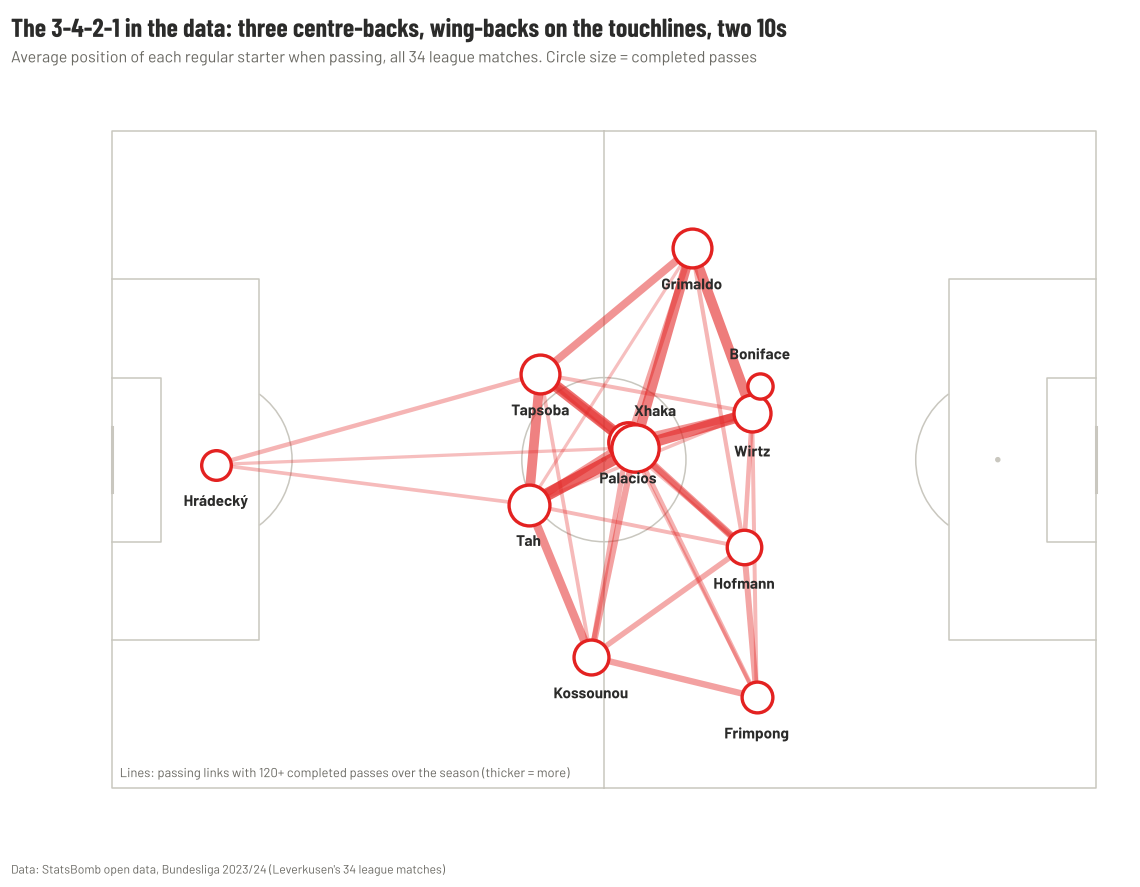

In [2]:
XI = ["Lukáš Hrádecký", "Odilon Kossonou", "Jonathan Tah", "Edmond Fayçal Tapsoba", "Jeremie Frimpong", "Granit Xhaka",
      "Exequiel Alejandro Palacios", "Alejandro Grimaldo García", "Jonas Hofmann", "Florian Wirtz", "Victor Okoh Boniface"]
LP = P[(P.team == LEV) & P.pass_outcome.isna()]
avg = LP[LP.player.isin(XI)].groupby("player").agg(x=("x", "mean"), y=("y", "mean"), n=("x", "size"))
pairs = LP[LP.player.isin(XI) & LP.pass_recipient.isin(XI)].groupby(["player", "pass_recipient"]).size().reset_index(name="n")
pairs["a"] = pairs[["player", "pass_recipient"]].min(axis=1); pairs["b"] = pairs[["player", "pass_recipient"]].max(axis=1)
links = pairs.groupby(["a", "b"]).n.sum().reset_index().sort_values("n", ascending=False)
pitch = Pitch(pitch_type="statsbomb", pitch_color="white", line_color="#C9C7BF", linewidth=1)
fig, ax = pitch.draw(figsize=(11, 7.3))
mx = links.n.max()
for _, r in links[links.n >= 120].iterrows():
    a, b = avg.loc[r.a], avg.loc[r.b]
    pitch.lines(a.x, a.y, b.x, b.y, ax=ax, lw=0.5 + 9 * r.n / mx, color=RED, alpha=0.18 + 0.6 * r.n / mx, zorder=1)
for name, r in avg.iterrows():
    pitch.scatter(r.x, r.y, s=200 + r.n / 4, ax=ax, color="white", edgecolors=RED, linewidth=2.2, zorder=3)
    off = {"Granit Xhaka": -4.6, "Florian Wirtz": 4.6, "Victor Okoh Boniface": -4.0}.get(name, 4.3)
    pitch.annotate(SHORT[name], (r.x + (2.5 if name == "Granit Xhaka" else 0), r.y + off), ax=ax, ha="center", va="center", fontsize=10, fontweight="bold", color=DARK, zorder=4)
ax.text(1, 79, "Lines: passing links with 120+ completed passes over the season (thicker = more)", fontsize=8.5, color=MUTED, va="bottom")
titles(fig, "The 3-4-2-1 in the data: three centre-backs, wing-backs on the touchlines, two 10s",
       "Average position of each regular starter when passing, all 34 league matches. Circle size = completed passes",
       SRC, y=0.99)
fig.savefig(FIGS / "04_shape_pass_network.png")
avg.assign(name=[SHORT[n] for n in avg.index]).sort_values("x").round(1)

## 05 · Control: the ball and the pitch

passes/match {'Leverkusen': 713.0, 'Opponents': 440.0} completion {'Leverkusen': 0.881, 'Opponents': 0.8}
mean pass share 0.617 min 0.389 Bayern Munich | matches above 50%: 28 | mean field tilt 0.656 | above 50%: 30


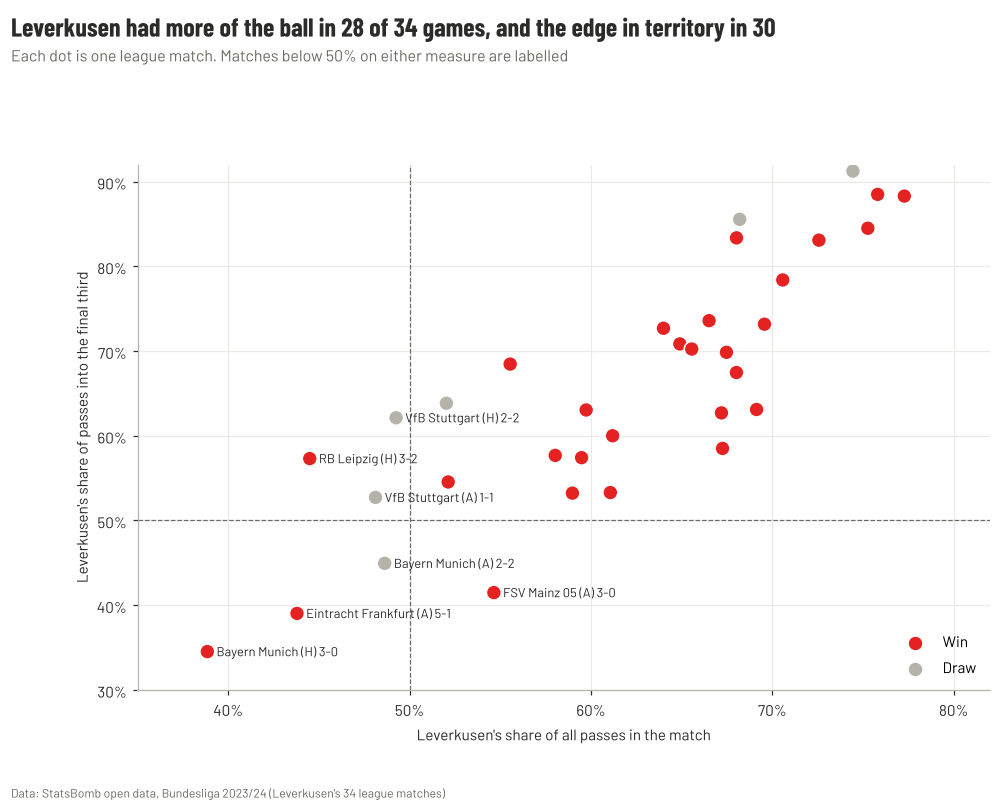

In [3]:
pm = P.groupby(["match_id", "side"]).size().unstack()
ft = P[P.ex >= 80].groupby(["match_id", "side"]).size().unstack()
C = pd.DataFrame({"pass_share": pm.Leverkusen / pm.sum(axis=1), "field_tilt": ft.Leverkusen / ft.sum(axis=1)}).join(M.set_index("match_id")[["opp", "res", "gf", "ga", "lev_home"]])
comp = P.groupby("side").pass_outcome.apply(lambda s: s.isna().mean())
print("passes/match", (P.groupby("side").size() / 34).round(0).to_dict(), "completion", comp.round(3).to_dict())
print("mean pass share", round(C.pass_share.mean(), 3), "min", round(C.pass_share.min(), 3), C.loc[C.pass_share.idxmin(), "opp"],
      "| matches above 50%:", int((C.pass_share > 0.5).sum()), "| mean field tilt", round(C.field_tilt.mean(), 3), "| above 50%:", int((C.field_tilt > 0.5).sum()))
fig, ax = plt.subplots(figsize=(10, 6.2))
C = C.sort_values("pass_share")
colors = C.res.map({"W": RED, "D": GREY})
ax.scatter(C.pass_share, C.field_tilt, s=95, c=colors, edgecolors="white", linewidth=1, zorder=3)
ax.axvline(0.5, color=MUTED, lw=0.8, ls="--"); ax.axhline(0.5, color=MUTED, lw=0.8, ls="--")
for _, r in C.iterrows():
    if r.pass_share < 0.5 or r.field_tilt < 0.5:
        ax.annotate(f"{r.opp} ({'H' if r.lev_home else 'A'}) {r.gf}-{r.ga}", (r.pass_share, r.field_tilt), xytext=(6, -3),
                    textcoords="offset points", fontsize=8.5, color=DARK)
ax.set_xlabel("Leverkusen's share of all passes in the match"); ax.set_ylabel("Leverkusen's share of passes into the final third")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0.35, 0.82); ax.set_ylim(0.3, 0.92); ax.grid(color="#ECEAE4", lw=0.8); ax.set_axisbelow(True)
ax.scatter([], [], c=RED, s=60, label="Win"); ax.scatter([], [], c=GREY, s=60, label="Draw")
ax.legend(loc="lower right", frameon=False)
titles(fig, f"Leverkusen had more of the ball in {int((C.pass_share > 0.5).sum())} of 34 games, and the edge in territory in {int((C.field_tilt > 0.5).sum())}",
       "Each dot is one league match. Matches below 50% on either measure are labelled",
       SRC)
fig.savefig(FIGS / "05_control_by_match.png")

## 06 · Where they win the ball back

            recoveries  pressures
side                             
Leverkusen        51.5      140.8
Opponents         43.3      195.1 
             Own third  Middle third  Attacking third
side                                                
Leverkusen      0.327         0.368            0.306
Opponents       0.447         0.348            0.205 
             Own third  Middle third  Attacking third
side                                                
Leverkusen      0.251         0.410            0.338
Opponents       0.350         0.465            0.185


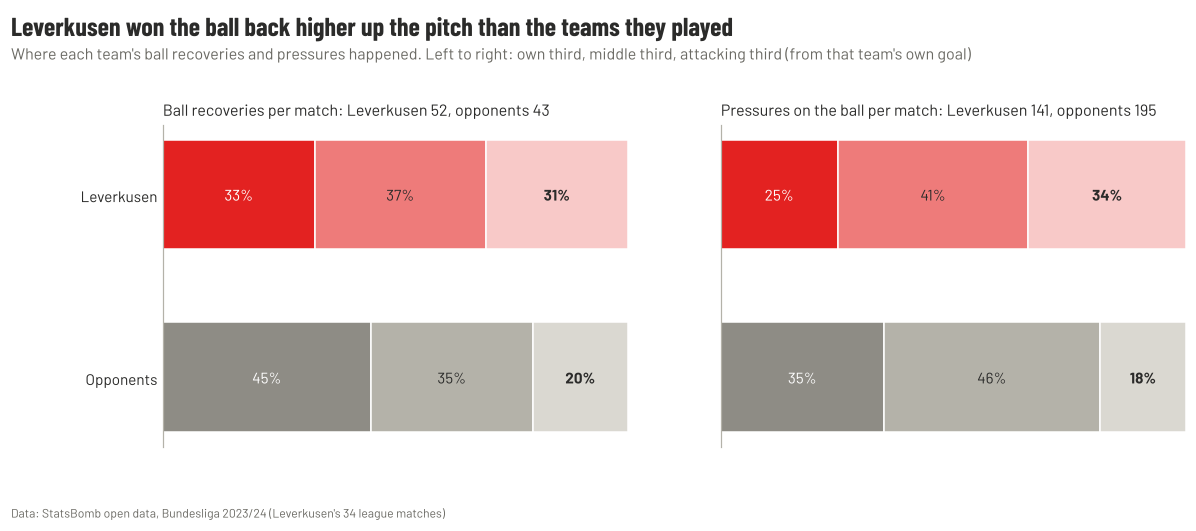

In [4]:
thirds = lambda s: pd.cut(s, [0, 40, 80, 120], labels=["Own third", "Middle third", "Attacking third"], include_lowest=True)
R = E[E.type == "Ball Recovery"]; PR = E[E.type == "Pressure"]
rec = R.groupby("side").x.apply(lambda s: thirds(s).value_counts(normalize=True)).unstack()
prs = PR.groupby("side").x.apply(lambda s: thirds(s).value_counts(normalize=True)).unstack()
per = pd.DataFrame({"recoveries": R.groupby("side").size() / 34, "pressures": PR.groupby("side").size() / 34}).round(1)
print(per, "\n", rec.round(3), "\n", prs.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
order = ["Own third", "Middle third", "Attacking third"]
for ax, (tab, lab, key) in zip(axes, [(rec, "Ball recoveries", "recoveries"), (prs, "Pressures on the ball", "pressures")]):
    for i, side in enumerate(["Leverkusen", "Opponents"]):
        left = 0
        for j, zone in enumerate(order):
            v = tab.loc[side, zone]
            col = [RED, "#EE7B7A", "#F8C9C8"][j] if side == "Leverkusen" else ["#8E8C85", GREY, "#DAD8D1"][j]
            ax.barh(1 - i, v, left=left, color=col, height=0.6, edgecolor="white")
            ax.text(left + v / 2, 1 - i, f"{v:.0%}", ha="center", va="center", fontsize=10,
                    color="white" if j == 0 else DARK, fontweight="bold" if zone == "Attacking third" else "normal")
            left += v
    ax.set_title(f"{lab} per match: Leverkusen {per.loc['Leverkusen', key]:.0f}, opponents {per.loc['Opponents', key]:.0f}",
                 fontsize=10.5, loc="left", color=DARK)
    ax.set_xlim(0, 1); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
axes[0].set_yticks([1, 0], ["Leverkusen", "Opponents"])
titles(fig, "Leverkusen won the ball back higher up the pitch than the teams they played",
       "Where each team's ball recoveries and pressures happened. Left to right: own third, middle third, attacking third (from that team's own goal)",
       SRC, y=1.08)
fig.savefig(FIGS / "06_where_they_win_the_ball.png")

## 07 · Wing-backs as attackers

,goals,assists,total
player,,,
Alejandro Grimaldo García,10,13,23
Victor Okoh Boniface,14,8,22
Florian Wirtz,11,10,21
Jeremie Frimpong,9,7,16
Jonas Hofmann,4,7,11
Amine Adli,4,5,9
Exequiel Alejandro Palacios,4,4,8
Patrik Schick,7,0,7
Nathan Tella,5,2,7


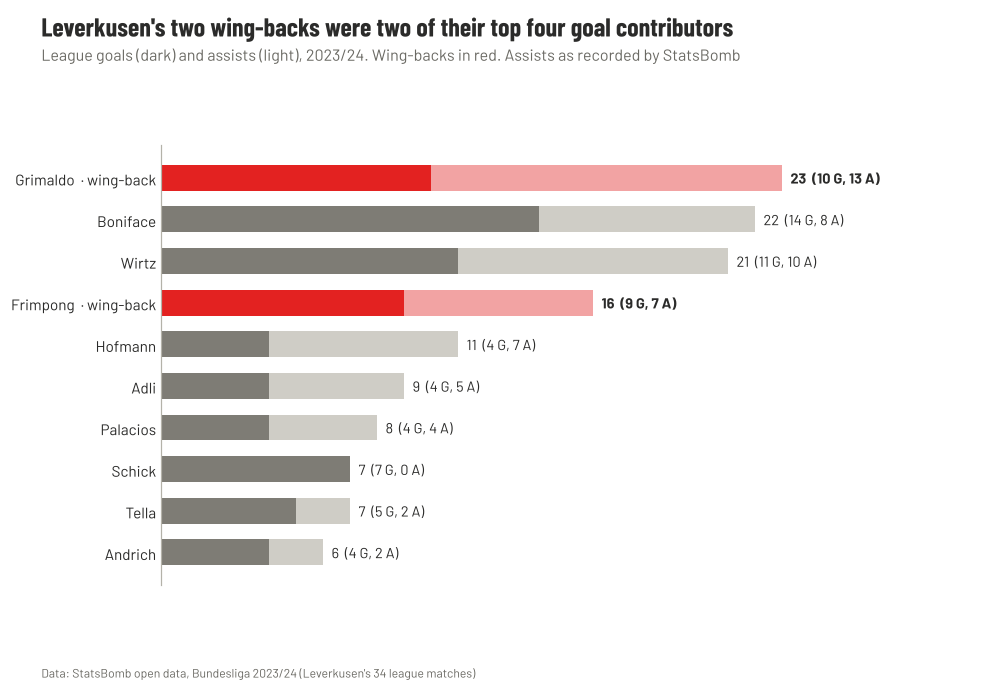

In [5]:
G = E[(E.type == "Shot") & (E.shot_outcome == "Goal") & (E.team == LEV)]
A = P[(P.team == LEV) & P.pass_goal_assist]
GA = pd.DataFrame({"goals": G.player.value_counts(), "assists": A.player.value_counts()}).fillna(0).astype(int)
GA["total"] = GA.goals + GA.assists
GA = GA.sort_values(["total", "goals"], ascending=False).head(10)
wb = {"Alejandro Grimaldo García", "Jeremie Frimpong"}
fig, ax = plt.subplots(figsize=(9.5, 5.2))
yy = np.arange(len(GA))[::-1]
for y0, (name, r) in zip(yy, GA.iterrows()):
    c1, c2 = (RED, PINK) if name in wb else ("#7E7C75", "#CFCDC6")
    ax.barh(y0, r.goals, color=c1, height=0.62); ax.barh(y0, r.assists, left=r.goals, color=c2, height=0.62)
    ax.text(r.total + 0.3, y0, f"{r.total}  ({r.goals} G, {r.assists} A)", va="center", fontsize=9.5, color=DARK, fontweight="bold" if name in wb else "normal")
ax.set_yticks(yy, [SHORT.get(n, n) + ("  · wing-back" if n in wb else "") for n in GA.index], fontsize=10)
ax.set_xlim(0, GA.total.max() + 7); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
titles(fig, "Leverkusen's two wing-backs were two of their top four goal contributors",
       "League goals (dark) and assists (light), 2023/24. Wing-backs in red. Assists as recorded by StatsBomb",
       SRC)
fig.savefig(FIGS / "07_wingback_goal_contributions.png")
GA

## 08 · Central play, not crosses

crosses/match {'Leverkusen': 12.9, 'Opponents': 7.3} 
box entries/match {'Leverkusen': 16.1, 'Opponents': 7.6} 
             Left wing  Central  Right wing
side                                      
Leverkusen      0.259    0.502       0.239
Opponents       0.242    0.415       0.342 
cross share of box entries {'Leverkusen': 0.161, 'Opponents': 0.235}


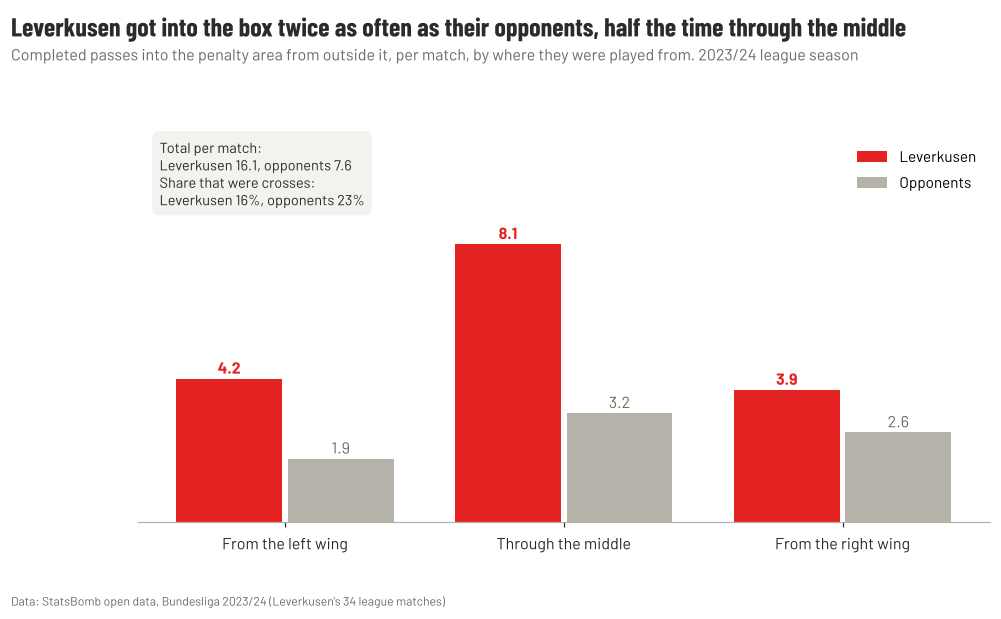

In [6]:
cr = P[P.pass_cross].groupby("side").size() / 34
box_ = P[P.pass_outcome.isna() & (P.ex >= 102) & P.ey.between(18, 62) & ~((P.x >= 102) & P.y.between(18, 62))]
lane = box_.groupby("side").y.apply(lambda s: pd.cut(s, [0, 18, 62, 80], labels=["Left wing", "Central", "Right wing"], include_lowest=True).value_counts(normalize=True)).unstack()
crossed = box_.groupby("side").pass_cross.mean()
print("crosses/match", cr.round(1).to_dict(), "\nbox entries/match", (box_.groupby("side").size() / 34).round(1).to_dict(), "\n", lane.round(3), "\ncross share of box entries", crossed.round(3).to_dict())
per_lane = (box_.groupby(["side"]).y.apply(lambda s: pd.cut(s, [0, 18, 62, 80], labels=["Left wing", "Central", "Right wing"], include_lowest=True).value_counts()).unstack() / 34)
per_lane = per_lane[["Left wing", "Central", "Right wing"]]
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(3)
ax.bar(x - 0.2, per_lane.loc["Leverkusen"], width=0.38, color=RED, label="Leverkusen")
ax.bar(x + 0.2, per_lane.loc["Opponents"], width=0.38, color=GREY, label="Opponents")
for i_, lane_ in enumerate(per_lane.columns):
    ax.text(i_ - 0.2, per_lane.loc["Leverkusen", lane_] + 0.15, f"{per_lane.loc['Leverkusen', lane_]:.1f}", ha="center", fontsize=10.5, color=RED, fontweight="bold")
    ax.text(i_ + 0.2, per_lane.loc["Opponents", lane_] + 0.15, f"{per_lane.loc['Opponents', lane_]:.1f}", ha="center", fontsize=10.5, color=MUTED)
ax.set_xticks(x, ["From the left wing", "Through the middle", "From the right wing"], fontsize=10.5)
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.legend(frameon=False, loc="upper right")
ax.set_ylim(0, per_lane.values.max() * 1.4)
ax.text(-0.45, per_lane.values.max() * 1.38, f"Total per match:\nLeverkusen {box_[box_.side == 'Leverkusen'].shape[0] / 34:.1f}, opponents {box_[box_.side == 'Opponents'].shape[0] / 34:.1f}\n"
        f"Share that were crosses:\nLeverkusen {crossed['Leverkusen']:.0%}, opponents {crossed['Opponents']:.0%}",
        ha="left", va="top", fontsize=9.5, color=DARK, bbox=dict(boxstyle="round,pad=0.5", fc=LIGHT, ec="none"))
titles(fig, "Leverkusen got into the box twice as often as their opponents, half the time through the middle",
       "Completed passes into the penalty area from outside it, per match, by where they were played from. 2023/24 league season",
       SRC)
fig.savefig(FIGS / "08_passes_into_the_box.png")

## 09 · Late goals

band        0-15  15-30  30-45  45+  45-60  60-75  75-90  90+
side                                                         
Leverkusen     9     11     11    6     14     16     14    8
Opponents      5      1      5    0      6      3      4    0 
points from 90+ goals: 9
                opponent score  points       change
0      VfB Stuttgart (H)   2-2       1  loss → draw
1         Hoffenheim (H)   2-1       2   draw → win
2      Bayern Munich (A)   2-2       1  loss → draw
3  Borussia Dortmund (A)   1-1       1  loss → draw
4         RB Leipzig (A)   3-2       2   draw → win
5           Augsburg (A)   1-0       2   draw → win


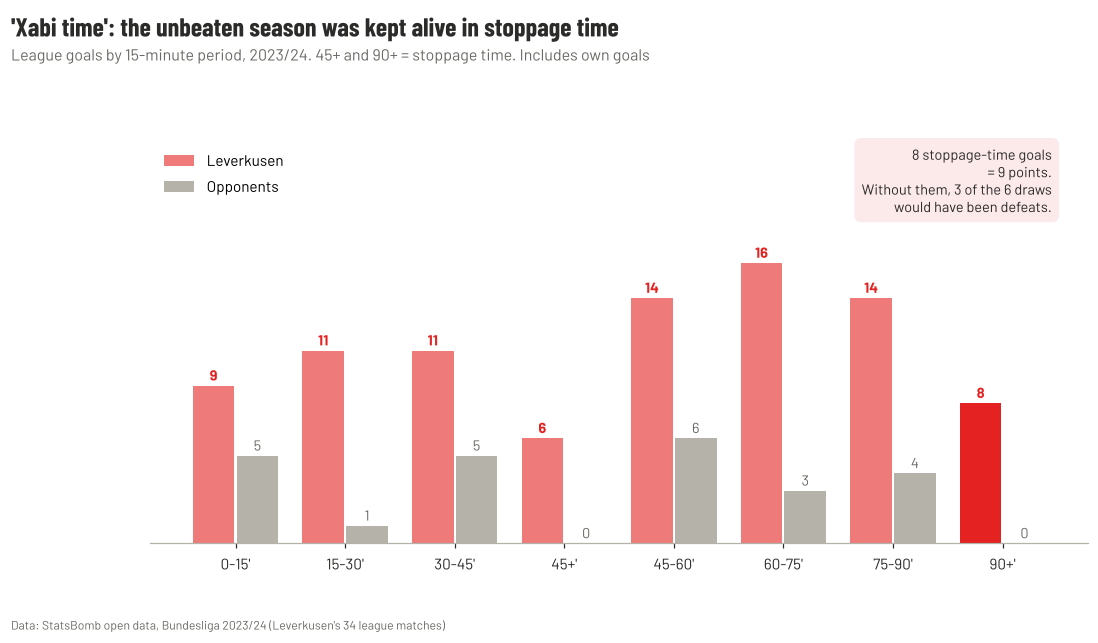

In [7]:
GL = E[((E.type == "Shot") & (E.shot_outcome == "Goal")) | (E.type == "Own Goal For")].copy()
def band(r):
    if r.period == 1:
        return "45+" if r.minute >= 45 else ["0-15", "15-30", "30-45"][min(r.minute // 15, 2)]
    if r.minute >= 90:
        return "90+"
    return ["45-60", "60-75", "75-90"][min((r.minute - 45) // 15, 2)]
GL["band"] = GL.apply(band, axis=1)
order = ["0-15", "15-30", "30-45", "45+", "45-60", "60-75", "75-90", "90+"]
tab = pd.crosstab(GL.band, GL.side).reindex(order).fillna(0).astype(int)
# points won by stoppage-time goals
pts = 0; saved = []
for _, r in M.iterrows():
    late = GL[(GL.match_id == r.match_id) & (GL.period == 2) & (GL.minute >= 90)]
    lf, la = (late.team == LEV).sum(), (late.team != LEV).sum()
    p = lambda a, b: 3 if a > b else 1 if a == b else 0
    d = p(r.gf, r.ga) - p(r.gf - lf, r.ga - la); pts += d
    if d: saved.append((f"{r.opp} ({'H' if r.lev_home else 'A'})", f"{r.gf}-{r.ga}", d, "loss → draw" if r.res == "D" else "draw → win"))
print(tab.T, "\npoints from 90+ goals:", pts); print(pd.DataFrame(saved, columns=["opponent", "score", "points", "change"]))
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(order))
ax.bar(x - 0.2, tab.Leverkusen, width=0.38, color=[RED if b == "90+" else "#EE7B7A" for b in order], label="Leverkusen")
ax.bar(x + 0.2, tab.Opponents, width=0.38, color=GREY, label="Opponents")
for i, b in enumerate(order):
    ax.text(i - 0.2, tab.loc[b, "Leverkusen"] + 0.3, tab.loc[b, "Leverkusen"], ha="center", fontsize=9.5, color=RED, fontweight="bold")
    ax.text(i + 0.2, tab.loc[b, "Opponents"] + 0.3, tab.loc[b, "Opponents"], ha="center", fontsize=9.5, color=MUTED)
ax.set_xticks(x, [b + "'" for b in order]); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.legend(frameon=False, loc="upper left"); ax.set_ylim(0, tab.values.max() * 1.45)
losses = sum(1 for s in saved if s[3] == "loss → draw")
ax.text(7.45, tab.values.max() * 1.42, f"{tab.loc['90+', 'Leverkusen']} stoppage-time goals\n= {pts} points.\nWithout them, {losses} of the 6 draws\nwould have been defeats.",
        ha="right", va="top", fontsize=9.5, color=DARK, bbox=dict(boxstyle="round,pad=0.5", fc="#FCE9E9", ec="none"))
titles(fig, "'Xabi time': the unbeaten season was kept alive in stoppage time",
       "League goals by 15-minute period, 2023/24. 45+ and 90+ = stoppage time. Includes own goals",
       SRC)
fig.savefig(FIGS / "09_goals_by_minute.png")